In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["figure.figsize"] = (10, 4)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)


In [2]:
advisor_roster = pd.read_csv("sources/advisor_roster.csv")
custodian_positions = pd.read_excel("sources/custodian_positions.xlsx")
meetings = pd.read_csv("sources/notion_export/Meetings 2b26fa77d1142f88db92d6b69dc697fd.csv")
clients = pd.read_csv("sources/notion_export/Clients 484b3fe4ea9195d2052e7bc37063ffc7.csv")

def parse_notion_folder(folder_path):
    rows = []
    for md_file in sorted(Path(folder_path).glob("*.md")):
        blocks = md_file.read_text(encoding="utf-8").strip().split("\n\n")
        row = {
            "page_id": md_file.stem.split()[-1],
            "Name": blocks[0].lstrip("# ").strip(),
        }
        for line in blocks[1].splitlines():
            if ":" in line:
                k, v = line.split(":", 1)
                row[k.strip()] = v.strip()
        row["Notes"] = "\n\n".join(blocks[2:]).strip() or None
        rows.append(row)
    return pd.DataFrame(rows)

clients_md = parse_notion_folder("sources/notion_export/Clients 484b3fe4ea9195d2052e7bc37063ffc7")
meetings_md = parse_notion_folder("sources/notion_export/Meetings 2b26fa77d1142f88db92d6b69dc697fd")

datasets = {
    "advisor_roster": advisor_roster,
    "custodian_positions": custodian_positions,
    "meetings": meetings,
    "clients": clients,
}


## 1. Overview & Missing Values


In [3]:
summary_rows = []
for name, df in datasets.items():
    for col in df.columns:
        missing = df[col].isna().sum()
        top_val = df[col].value_counts(dropna=True).index[0] if df[col].dropna().shape[0] else None
        top_cnt = df[col].value_counts(dropna=True).iloc[0] if df[col].dropna().shape[0] else 0
        summary_rows.append({
            "dataset": name,
            "column": col,
            "dtype": str(df[col].dtype),
            "rows": len(df),
            "missing": missing,
            "missing_%": round(missing / len(df) * 100, 1),
            "nunique": df[col].nunique(dropna=True),
            "most_common": f"{top_val} ({top_cnt})"
        })
summary_df = pd.DataFrame(summary_rows)
summary_df


Out[0]: 
                dataset          column    dtype  rows  missing  missing_%  \
0        advisor_roster      advisor_id      str     7        0        0.0   
1        advisor_roster       full_name      str     7        0        0.0   
2        advisor_roster            role      str     7        0        0.0   
3        advisor_roster          office      str     7        0        0.0   
4   custodian_positions  Account_Number      str    53        0        0.0   
5   custodian_positions  Account_Holder      str    53        0        0.0   
6   custodian_positions    Account_Type      str    53        0        0.0   
7   custodian_positions    Market_Value    int64    53        0        0.0   
8   custodian_positions      Cost_Basis  float64    53       49       92.5   
9   custodian_positions        Currency      str    53        0        0.0   
10  custodian_positions      As_Of_Date      str    53        0        0.0   
11  custodian_positions       Custodian      str    53 

,dataset,column,dtype,rows,missing,missing_%,nunique,most_common
0,advisor_roster,advisor_id,str,7,0,0.0,7,ADV-001 (1)
1,advisor_roster,full_name,str,7,0,0.0,7,Priya Raman (1)
2,advisor_roster,role,str,7,0,0.0,3,Advisor (4)
3,advisor_roster,office,str,7,0,0.0,4,San Francisco (2)
4,custodian_positions,Account_Number,str,53,0,0.0,53,CU-5001 (1)
5,custodian_positions,Account_Holder,str,53,0,0.0,49,Patrick Brennan (2)
6,custodian_positions,Account_Type,str,53,0,0.0,8,Individual (39)
7,custodian_positions,Market_Value,int64,53,0,0.0,46,670000 (2)
8,custodian_positions,Cost_Basis,float64,53,49,92.5,4,1980000.0 (1)
9,custodian_positions,Currency,str,53,0,0.0,3,USD (51)


## 2. Common Values & Dirty Categorical Labels


In [4]:
for name, cols in [
    ("advisor_roster", ["role", "office"]),
    ("custodian_positions", ["Custodian", "Account_Type", "Currency", "As_Of_Date"]),
    ("meetings", ["Type", "Attendee"]),
    ("clients", ["Status", "Segment", "Risk Profile", "Fee Schedule", "Advisor", "Service Rep", "Tags"]),
]:
    print(f"=== {name} ===")
    for col in cols:
        vc = datasets[name][col].value_counts(dropna=False).to_dict()
        print(f"  {col}: {vc}")


=== advisor_roster ===
  role: {'Advisor': 4, 'Relationship Manager': 2, 'Senior Advisor': 1}
  office: {'San Francisco': 2, 'Chicago': 2, 'New York': 2, 'Boston': 1}
=== custodian_positions ===
  Custodian: {'Schwab': 26, 'Fidelity': 19, 'Pershing': 6, 'Lombard Intl': 1, 'Pictet': 1}
  Account_Type: {'Individual': 39, 'Joint WROS': 3, 'IRA': 3, 'Roth IRA': 3, 'Trust-Rev': 2, 'Rollover IRA': 1, 'Corporate': 1, 'Joint TIC': 1}
  Currency: {'USD': 51, 'EUR': 1, 'CHF': 1}
  As_Of_Date: {'2025-06-30': 50, '2024-12-31': 1, '2023-09-30': 1, '2024-09-30': 1}
=== meetings ===
  Type: {'Review': 9, 'Annual Review': 2, 'Prospecting': 2, 'Check-in': 1, 'QBR': 1, 'Intro Call': 1, 'Discovery': 1, 'Onboarding': 1}
  Attendee: {'Priya Raman': 3, 'Marcus Webb': 3, 'James Okafor': 3, 'Grace Bennett': 2, 'Elena Sokolova': 1, 'Sofia Marchetti': 1, 'David Feldman': 1, nan: 1, 'P. Raman': 1, 'A. Novak': 1, 'E. Sokolova': 1}
=== clients ===
  Status: {'Active': 44, 'Prospect': 5, 'Legacy': 4, 'Client': 1, '

## 3. Cross-Dataset Relationship Analysis


In [5]:
roster_names = set(advisor_roster["full_name"])
client_advisors = set(clients["Advisor"].dropna())
meeting_attendees = set(meetings["Attendee"].dropna())

print("Advisors in Clients not matching Roster:", client_advisors - roster_names)
print("Attendees in Meetings not matching Roster:", meeting_attendees - roster_names)

client_names = set(clients["Name"].dropna())
meeting_clients = set(meetings["Client"].dropna())
custodian_holders = set(custodian_positions["Account_Holder"].dropna())

print("\nMeeting Clients not exact-matching Clients table:", meeting_clients - client_names)
print(f"\nCustodian Account_Holders exact match: {len(custodian_holders & client_names)} / {len(custodian_holders)}")
print("Unmatched Custodian Account_Holders:", sorted(custodian_holders - client_names))
print("Clients without exact Custodian match:", sorted(client_names - custodian_holders))


Advisors in Clients not matching Roster: {'E. Sokolova', 'P. Raman'}
Attendees in Meetings not matching Roster: {'E. Sokolova', 'A. Novak', 'P. Raman'}

Meeting Clients not exact-matching Clients table: {'Bob Chen', 'Redwood Capital'}

Custodian Account_Holders exact match: 38 / 49
Unmatched Custodian Account_Holders: ['Ada Okonkwo Revocable Trust', 'Bill Fitzgerald', 'Bob & Linda Chen', 'Carlos Vasquez', 'G. Whitfield', 'Megan & Tom Sullivan', 'Nakamura Holdings LLC', 'Nakamura, Kenji', 'Priyanka Mehta', 'Rachel & Daniel Abramson', 'Thompson Joint']
Clients without exact Custodian match: ['Ada Okonkwo', 'Amara Nwosu', 'Bill Thompson', 'Daniel Abramson', 'Diego Vargas', 'George Whitfield', 'Gerald Voss', 'Isabelle Fournier', 'Kenji Nakamura', 'Klaus Bauer', 'Linda Chen', 'Megan Sullivan', 'Miguel Costa', 'Petrov, Dmitri', 'Rachel Abramson', 'Sarah Thompson', 'Susan Fairbanks', 'Tom Sullivan', 'William Fitzgerald']


## 4. Visualizations


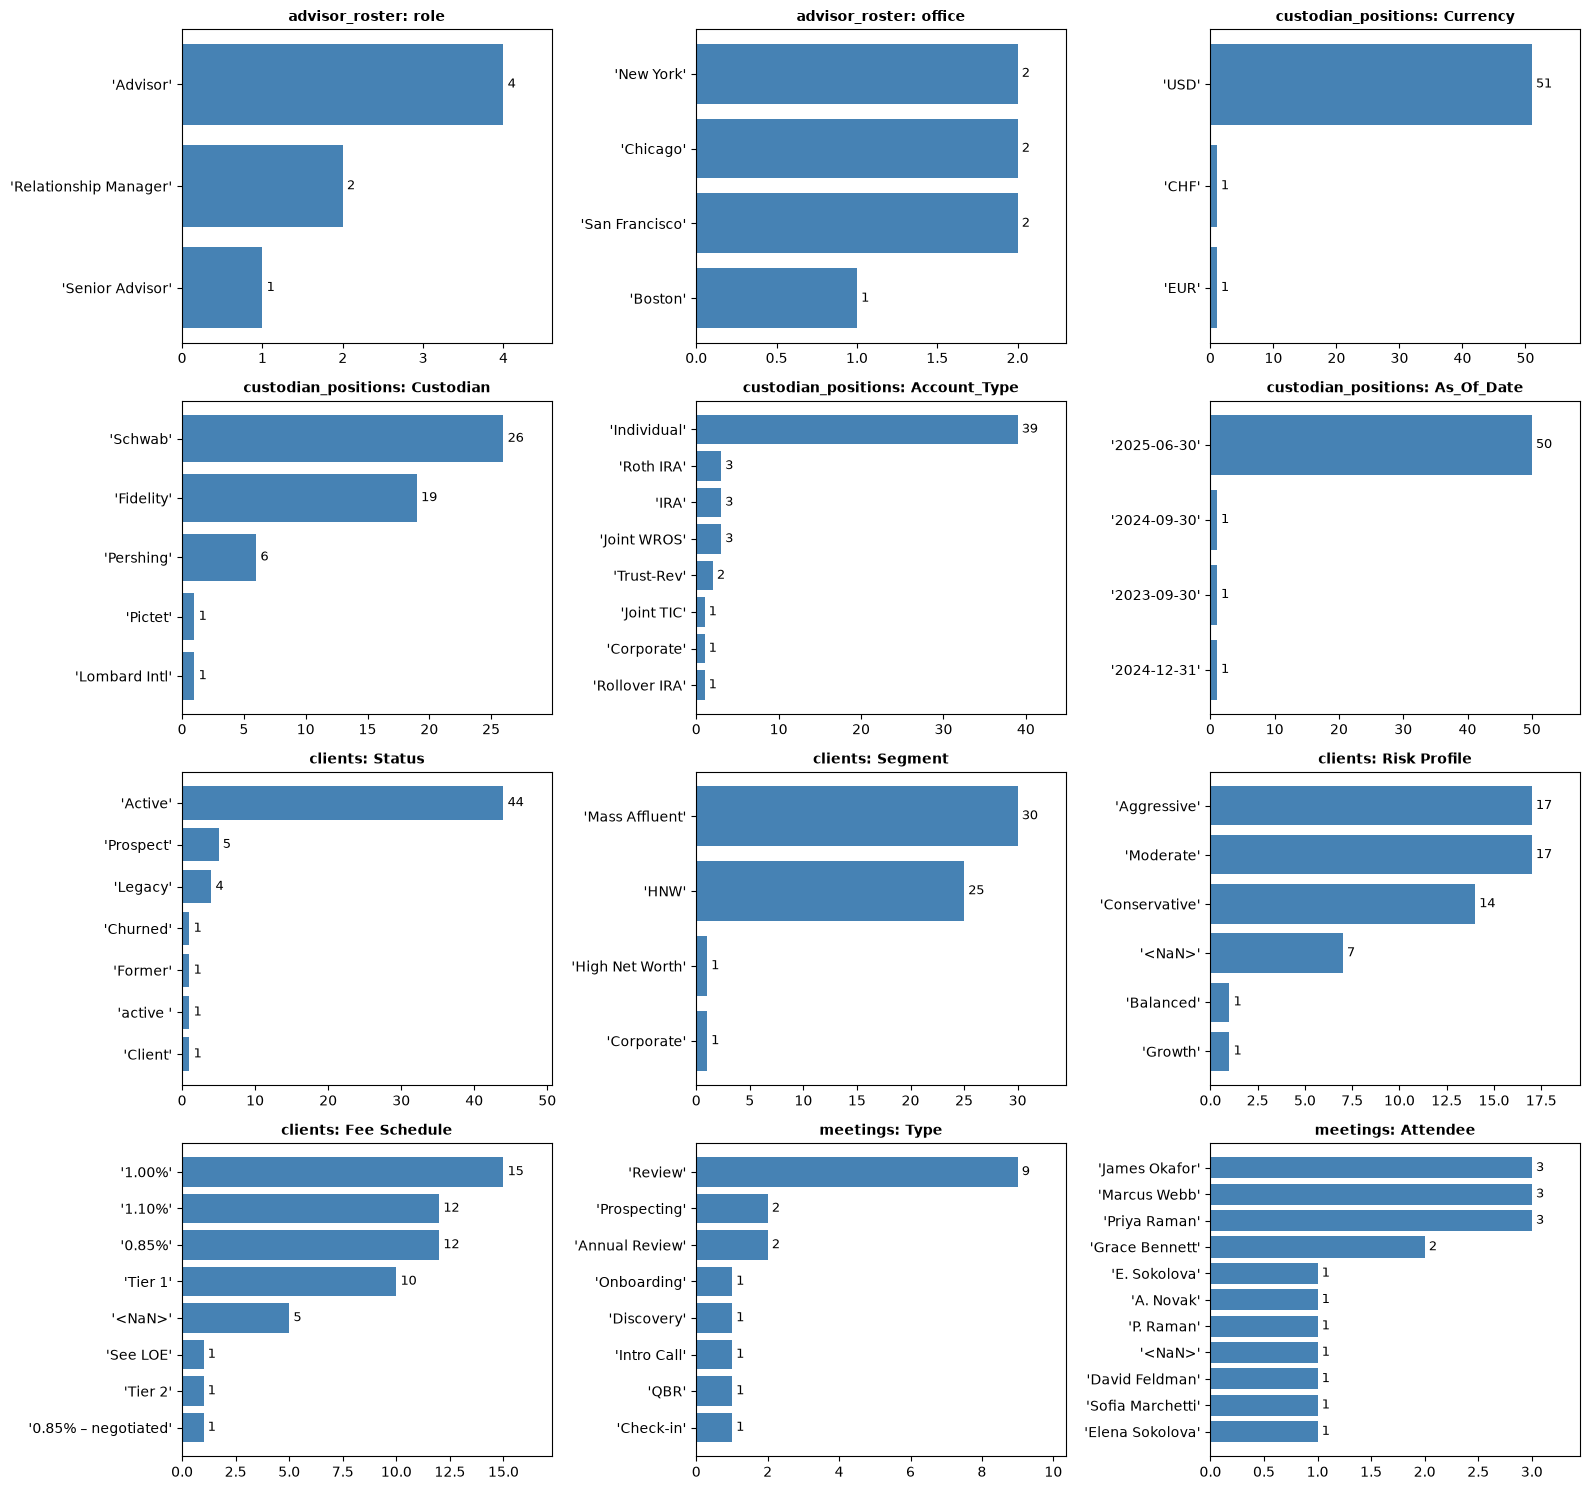

In [6]:
# Raw Categorical Distributions across all datasets (including NaNs & unnormalized labels)
cat_cols = [
    ("advisor_roster", "role"),
    ("advisor_roster", "office"),
    ("custodian_positions", "Currency"),
    ("custodian_positions", "Custodian"),
    ("custodian_positions", "Account_Type"),
    ("custodian_positions", "As_Of_Date"),
    ("clients", "Status"),
    ("clients", "Segment"),
    ("clients", "Risk Profile"),
    ("clients", "Fee Schedule"),
    ("meetings", "Type"),
    ("meetings", "Attendee"),
]

fig, axes = plt.subplots(4, 3, figsize=(16, 15))
for ax, (ds_name, col) in zip(axes.flat, cat_cols):
    vc = datasets[ds_name][col].fillna("<NaN>").astype(str).apply(repr).value_counts().sort_values()
    bars = ax.barh(vc.index, vc.values, color="steelblue")
    ax.bar_label(bars, padding=3, fontsize=9)
    ax.set_title(f"{ds_name}: {col}", fontsize=10, fontweight="bold")
    ax.margins(x=0.15)

plt.tight_layout()
plt.show()


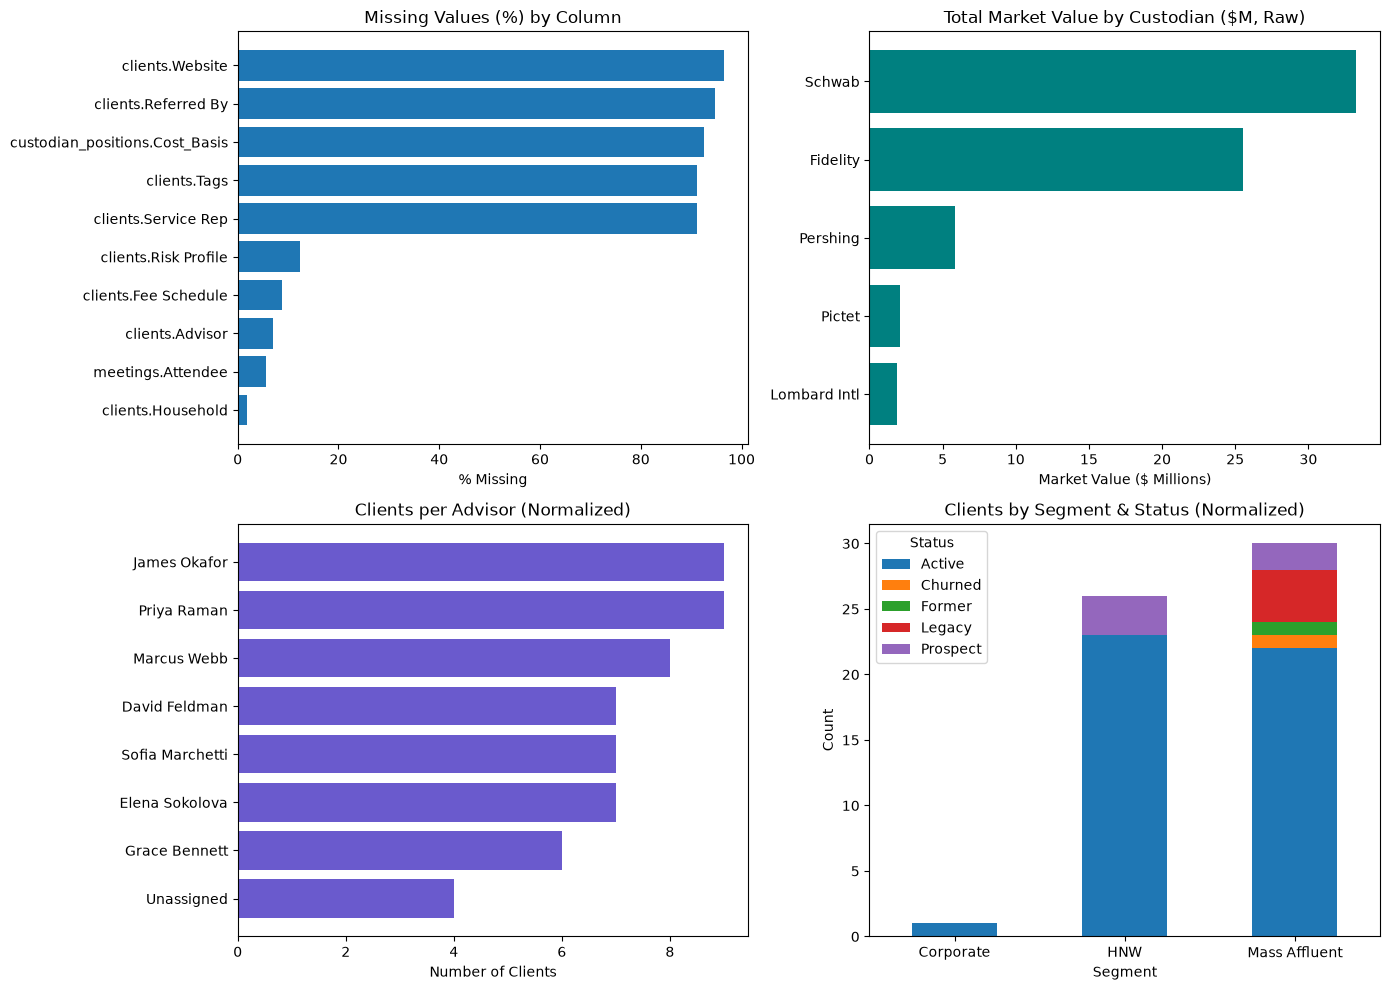

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Missing values (%) across columns with missing data
miss = summary_df[summary_df["missing"] > 0].sort_values("missing_%")
axes[0, 0].barh(miss["dataset"] + "." + miss["column"], miss["missing_%"])
axes[0, 0].set_title("Missing Values (%) by Column")
axes[0, 0].set_xlabel("% Missing")

# 2. Total Market Value by Custodian
aum_by_cust = custodian_positions.groupby("Custodian")["Market_Value"].sum().sort_values() / 1e6
axes[0, 1].barh(aum_by_cust.index, aum_by_cust.values, color="teal")
axes[0, 1].set_title("Total Market Value by Custodian ($M, Raw)")
axes[0, 1].set_xlabel("Market Value ($ Millions)")

# 3. Client Count by Advisor (normalizing abbreviated names)
adv_norm = clients["Advisor"].replace({"P. Raman": "Priya Raman", "E. Sokolova": "Elena Sokolova"}).fillna("Unassigned")
adv_counts = adv_norm.value_counts().sort_values()
axes[1, 0].barh(adv_counts.index, adv_counts.values, color="slateblue")
axes[1, 0].set_title("Clients per Advisor (Normalized)")
axes[1, 0].set_xlabel("Number of Clients")

# 4. Client Status vs Segment (normalized)
status_clean = clients["Status"].str.strip().str.title().replace({"Client": "Active"})
seg_clean = clients["Segment"].replace({"High Net Worth": "HNW"})
ct = pd.crosstab(seg_clean, status_clean)
ct.plot(kind="bar", stacked=True, ax=axes[1, 1], rot=0)
axes[1, 1].set_title("Clients by Segment & Status (Normalized)")
axes[1, 1].set_ylabel("Count")

plt.tight_layout()
plt.show()


In [8]:
# Joined view: Client Segment vs Custodian Market Value (for exact-matched clients)
merged = custodian_positions.merge(clients, left_on="Account_Holder", right_on="Name", how="left")
merged["Match_Status"] = np.where(merged["Name"].notna(), "Exact Match", "Unmatched / Entity / Joint")
merged.groupby(["Match_Status", "Custodian"])["Market_Value"].agg(["count", "sum"])


Out[0]: 
                                         count       sum
Match_Status               Custodian                    
Exact Match                Fidelity         16  11280000
                           Lombard Intl      1   1875000
                           Pershing          5   5185000
                           Pictet            1   2100000
                           Schwab           19  24210200
Unmatched / Entity / Joint Fidelity          3  14230000
                           Pershing          1    670000
                           Schwab            7   9022900


count       sum
Match_Status               Custodian                    
Exact Match                Fidelity         16  11280000
                           Lombard Intl      1   1875000
                           Pershing          5   5185000
                           Pictet            1   2100000
                           Schwab           19  24210200
Unmatched / Entity / Joint Fidelity          3  14230000
                           Pershing          1    670000
                           Schwab            7   9022900

## 5. Extract Page Content & Properties from Notion Markdown Exports


In [9]:
from pathlib import Path

def parse_notion_folder(folder_path):
    rows = []
    for md_file in sorted(Path(folder_path).glob("*.md")):
        blocks = md_file.read_text(encoding="utf-8").strip().split("\n\n")
        row = {
            "page_id": md_file.stem.split()[-1],
            "Name": blocks[0].lstrip("# ").strip(),
        }
        for line in blocks[1].splitlines():
            if ":" in line:
                k, v = line.split(":", 1)
                row[k.strip()] = v.strip()
        row["Notes"] = "\n\n".join(blocks[2:]).strip() or None
        rows.append(row)
    return pd.DataFrame(rows)

clients_md = parse_notion_folder("sources/notion_export/Clients 484b3fe4ea9195d2052e7bc37063ffc7")
meetings_md = parse_notion_folder("sources/notion_export/Meetings 2b26fa77d1142f88db92d6b69dc697fd")

print(f"Extracted {len(clients_md)} client pages ({clients_md['Notes'].notna().sum()} with notes)")
print(f"Extracted {len(meetings_md)} meeting pages ({meetings_md['Notes'].notna().sum()} with notes)")

# Show ALL columns for extracted Client & Meeting pages (no dropped columns)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
display(clients_md[clients_md["Notes"].notna()])
display(meetings_md[meetings_md["Notes"].notna()])


Extracted 57 client pages (13 with notes)
Extracted 18 meeting pages (4 with notes)


,page_id,Name,Status,Advisor,Household,Segment,Client Since,Risk Profile,Fee Schedule,Notes,Tags,Service Rep,Website,Referred By
1,74cdc7071d5ac59694c0cef751a20f3b,Adaeze Osei,Legacy,David Feldman,Osei,Mass Affluent,"November 2, 2019",Aggressive,1.00%,Came across in the **Harborline** acquisition. Well looked after — David picked her up straight away.,NaN,NaN,NaN,NaN
6,e0ea94eab381f9be6af6053dcea6adef,Bill Thompson,Former,James Okafor,Thompson,Mass Affluent,"April 27, 2013",Moderate,Tier 1,Joint account with his wife Sarah. Left us in 2023 — we're winding down the last position.,NaN,NaN,NaN,NaN
16,2f805d00ae83a3f8912fb9e4de2a517d,Francesca Bianchi,Active,Sofia Marchetti,Bianchi,HNW,"July 12, 2019",Aggressive,1.10%,Based in Geneva; account held with a Swiss custodian in **francs**.,NaN,NaN,NaN,NaN
17,c4eea67c71c42bc50d60fac055a7f817,George Whitfield,Legacy,NaN,Whitfield,Mass Affluent,"November 2, 2019",NaN,1.00%,Another **Harborline** client. Anna was looking after him before she left the firm — needs reassigning to someone current.,NaN,A. Novak,NaN,NaN
26,f60fdd79238271eb1e79a13e700f29d7,Kenji Nakamura,Client,P. Raman,Nakamura,Corporate,"May 30, 2018",Aggressive,0.85%,Authorized signer on **Nakamura Holdings LLC** (the family investment company — that's where the bulk of the assets sit). Also opened a **personal IRA** last year. Not sure whether we report the IRA under the LLC household or treat it as his own — flag for ops.,NaN,NaN,www.nakamura-holdings.example,NaN
29,47f0cf4daee3f0c2a4e40c8dbe824c4f,Linda Chen,Active,Priya Raman,NaN,Mass Affluent,"March 11, 2016",Moderate,0.85%,Wife of Robert Chen — same household. They hold a **joint account** together; Robert also has a rollover IRA under his own name. Main point of contact is Robert.,NaN,Marcus Webb,NaN,NaN
31,511f8b2f3888427eb1de64c9d64b5928,Louis Petit,Legacy,NaN,Petit,Mass Affluent,"November 2, 2019",Conservative,0.85%,**Harborline** book. Never got a proper advisor of record assigned.,NaN,Marcus Webb,NaN,NaN
32,504504a658098bb6f57fb7ae5ad93776,Maria Delgado,Legacy,NaN,Delgado,Mass Affluent,"November 2, 2019",NaN,1.10%,Came over in the **Harborline** acquisition back in 2019. Marcus has been servicing the account but she doesn't really have a proper advisor of record assigned — should sort that out.,NaN,Marcus Webb,NaN,NaN
34,32e22ca3b8a148db06155490de3fcff6,Mei Lin Tan,Active,Sofia Marchetti,Tan Household,Mass Affluent,"August 9, 2021",Conservative,1.10%,Prefers to be contacted by email only.,NaN,NaN,NaN,NaN
42,4ab17f9253d0bc71de5c4185515370ce,"Petrov, Dmitri",active,E. Sokolova,Petrov Household,Mass Affluent,"January 19, 2017",Aggressive,1.00%,Might be a duplicate — I think this got created a second time during the CRM import. Same person as the other Dmitri Petrov record.,NaN,NaN,NaN,NaN


,page_id,Name,Client,Type,Date,Attendee,Notes
5,0207617519fc6144985837ff683d1c9f,Intro Call — Redwood Capital,Redwood Capital,Prospecting,"June 8, 2025",James Okafor,Referred lead — not in the CRM yet.
8,3e5f69e5eeb268957229b3569ed68d8e,Portfolio check-in — Bob Chen,Bob Chen,Review,"January 15, 2025",Priya Raman,Quick portfolio check-in with Bob.
14,7fbe83c9e9cc7ce37420b41a9a5e57a1,Review — Nakamura,Kenji Nakamura,Review,"April 30, 2025",P. Raman,Family still deciding whether Kenji's IRA sits under the LLC or on its own.
17,0ec3b6934e8eb3d3cc516609e44b229f,Review — Thompson,Bill Thompson,Review,"May 15, 2025",James Okafor,"Discussed winding down, but they asked about possibly re-engaging next year."


## 6. Column-by-Column Missingness & Retention Audit (Why You Can/Can't Drop Columns)


In [10]:
# 1) clients.Service Rep (91.2% missing — 5 non-null rows)
# DO NOT DROP: For 3 Legacy Harborline clients (Maria Delgado, George Whitfield, Louis Petit)
# where Advisor is NaN, Service Rep is the ONLY staff link.
display(clients_md[clients_md["Service Rep"].notna() | clients_md["Advisor"].isna()][["Name", "Status", "Advisor", "Service Rep", "Notes"]])

# 2) clients.Tags (91.2% missing — 5 non-null rows)
# DO NOT DROP: Contains critical compliance/status flags ('Deceased' on Active client Omar Farouk,
# 'Do Not Contact' on Wei Zhang, 'Held Away' on Gerald Voss, 'VIP', 'ESG').
display(clients_md[clients_md["Tags"].notna()][["Name", "Status", "Advisor", "Tags", "Notes"]])

# 3) clients.Fee Schedule (8.8% missing) & Risk Profile (12.3% missing)
# Missingness is structural: all 5 missing Fee Schedules (and 5 of 7 missing Risk Profiles)
# are Status == 'Prospect' (not onboarded yet). The other 2 missing Risk Profiles are Legacy Harborline accounts.
display(clients_md[clients_md["Fee Schedule"].isna() | clients_md["Risk Profile"].isna()][["Name", "Status", "Advisor", "Risk Profile", "Fee Schedule", "Notes"]])

# 4) clients.Referred By (94.7% missing — 3 rows) & Website (96.5% missing — 2 rows)
# Optional metadata; Website only has dummy URLs ('www.example-chen.com', 'www.nakamura-holdings.example'),
# safe to drop for analytics unless tracking referrals/domains.
display(clients_md[clients_md["Referred By"].notna() | clients_md["Website"].notna()][["Name", "Status", "Website", "Referred By", "Notes"]])

# 5) custodian_positions.Cost_Basis (92.5% missing — only 4 of 53 accounts populated)
# Only populated on 4 Schwab accounts; unusable for firm-wide unrealized gain/loss,
# so exclude from firm-wide aggregations with this caveat documented.
display(custodian_positions[custodian_positions["Cost_Basis"].notna()])


,Name,Status,Advisor,Service Rep,Notes
17,George Whitfield,Legacy,NaN,A. Novak,Another **Harborline** client. Anna was looking after him before she left the firm — needs reassigning to someone current.
25,Joris Vandermeer,Active,NaN,NaN,NaN
29,Linda Chen,Active,Priya Raman,Marcus Webb,Wife of Robert Chen — same household. They hold a **joint account** together; Robert also has a rollover IRA under his own name. Main point of contact is Robert.
31,Louis Petit,Legacy,NaN,Marcus Webb,**Harborline** book. Never got a proper advisor of record assigned.
32,Maria Delgado,Legacy,NaN,Marcus Webb,Came over in the **Harborline** acquisition back in 2019. Marcus has been servicing the account but she doesn't really have a proper advisor of record assigned — should sort that out.
45,Robert Chen,Active,Priya Raman,Marcus Webb,NaN


,Name,Status,Advisor,Tags,Notes
4,Astrid Johansson,Active,Grace Bennett,VIP,NaN
18,Gerald Voss,Active,Grace Bennett,Held Away,NaN
39,Omar Farouk,Active,Sofia Marchetti,Deceased,NaN
44,Rajesh Iyer,Active,Grace Bennett,"VIP, ESG",NaN
54,Wei Zhang,Active,James Okafor,Do Not Contact,Reviews the portfolio with the team each quarter.


,Name,Status,Advisor,Risk Profile,Fee Schedule,Notes
2,Amara Nwosu,Prospect,David Feldman,NaN,NaN,NaN
11,Diego Vargas,Prospect,Sofia Marchetti,NaN,NaN,NaN
17,George Whitfield,Legacy,NaN,NaN,1.00%,Another **Harborline** client. Anna was looking after him before she left the firm — needs reassigning to someone current.
27,Klaus Bauer,Prospect,David Feldman,NaN,NaN,NaN
32,Maria Delgado,Legacy,NaN,NaN,1.10%,Came over in the **Harborline** acquisition back in 2019. Marcus has been servicing the account but she doesn't really have a proper advisor of record assigned — should sort that out.
35,Miguel Costa,Prospect,Sofia Marchetti,NaN,NaN,NaN
49,Susan Fairbanks,Prospect,James Okafor,NaN,NaN,NaN


,Name,Status,Website,Referred By,Notes
26,Kenji Nakamura,Client,www.nakamura-holdings.example,NaN,Authorized signer on **Nakamura Holdings LLC** (the family investment company — that's where the bulk of the assets sit). Also opened a **personal IRA** last year. Not sure whether we report the IRA under the LLC household or treat it as his own — flag for ops.
36,Nadia Haddad,Active,NaN,Gregory Palme,NaN
45,Robert Chen,Active,www.example-chen.com,NaN,NaN
48,Sophie Laurent,Active,NaN,Emily Harrington,Referred by an existing client.
51,Tobias Kruger,Active,NaN,Seminar 2023,NaN


,Account_Number,Account_Holder,Account_Type,Market_Value,Cost_Basis,Currency,As_Of_Date,Custodian
0,CU-5001,Bob & Linda Chen,Joint WROS,2340500,1980000.0,USD,2025-06-30,Schwab
1,CU-5002,Robert Chen,Rollover IRA,890200,750000.0,USD,2025-06-30,Schwab
3,CU-5004,Maria Delgado,Individual,1240000,1100000.0,USD,2024-12-31,Schwab
14,CU-6004,Patrick Brennan,Individual,2100000,1750000.0,USD,2025-06-30,Schwab


## 7. Data Cleanup Across All Datasets (Clients, Meetings, Custodian Positions)


In [11]:
clients_clean = clients_md.copy()
meetings_clean = meetings_md.copy()
positions_clean = custodian_positions.copy()

# --- A. CLIENTS CLEANUP ---
# 1. Drop useless columns (Service Rep per Dana: "just day-to-day paperwork, don't treat as advisor";
#    Website: dummy URLs; Cost_Basis per Dana: "Ignore cost basis, just for tax").
#    Record Flag_Departed_Rep = True where Service Rep was A. Novak before dropping.
clients_clean["Flag_Departed_Rep"] = clients_clean["Service Rep"].eq("A. Novak")
clients_clean = clients_clean.drop(columns=["Service Rep", "Website"])

# 2. Collapse duplicate CRM record: "Petrov, Dmitri" -> keep "Dmitri Petrov" (note + Dana Slack 11:52)
clients_clean = clients_clean[clients_clean["Name"] != "Petrov, Dmitri"].reset_index(drop=True)

# 3. Fill missing Household from note: Linda Chen -> "Chen Household"
clients_clean.loc[clients_clean["Name"] == "Linda Chen", "Household"] = "Chen Household"
clients_clean["Household"] = clients_clean["Household"].str.replace(r"\s+Household$", "", regex=True) + " Household"

# 4. Preserve Harborline lineage before mapping Status -> ACTIVE | INACTIVE | PROSPECT
clients_clean["Lineage"] = clients_clean["Status"].map({"Legacy": "Harborline"})
status_map = {
    "Active": "ACTIVE", "active": "ACTIVE", "ACTIVE": "ACTIVE",
    "Client": "ACTIVE", "Legacy": "ACTIVE",
    "Former": "INACTIVE", "Churned": "INACTIVE", "Inactive": "INACTIVE",
    "Prospect": "PROSPECT",
}
clients_clean["Status"] = clients_clean["Status"].str.strip().map(status_map)

# 5. Normalize Advisor abbreviations, Segment, Risk Profile, Fee Schedule casing, and Client Since dates
adv_map = {"P. Raman": "Priya Raman", "E. Sokolova": "Elena Sokolova"}
clients_clean["Advisor"] = clients_clean["Advisor"].replace(adv_map)
clients_clean["Segment"] = clients_clean["Segment"].replace({"High Net Worth": "HNW"})
clients_clean["Risk Profile"] = clients_clean["Risk Profile"].replace({"3 - Moderate": "Moderate"})
clients_clean["Fee Schedule"] = clients_clean["Fee Schedule"].replace({"tier 1": "Tier 1"})
clients_clean["Client Since"] = pd.to_datetime(clients_clean["Client Since"], format="mixed").dt.strftime("%Y-%m-%d")

# --- B. MEETINGS CLEANUP ---
# 1. Remove departed contractor A. Novak & normalize abbreviated Advisor names in Attendee
meetings_clean["Attendee"] = meetings_clean["Attendee"].replace({"A. Novak": None, **adv_map})

# 2. Resolve Client name aliases in meetings ("Bob Chen" -> "Robert Chen", "Petrov, Dmitri" -> "Dmitri Petrov")
meetings_clean["Client"] = meetings_clean["Client"].replace({
    "Bob Chen": "Robert Chen",
    "Petrov, Dmitri": "Dmitri Petrov",
})

# 3. Map meeting Type -> Canonical interaction_type (REVIEW | PROSPECTING | ONBOARDING | OTHER) & ISO Date
interaction_type_map = {
    "Review": "REVIEW", "Annual Review": "REVIEW", "QBR": "REVIEW", "Check-in": "REVIEW",
    "Prospecting": "PROSPECTING", "Intro Call": "PROSPECTING", "Discovery": "PROSPECTING",
    "Onboarding": "ONBOARDING",
}
meetings_clean["interaction_type"] = meetings_clean["Type"].map(interaction_type_map).fillna("OTHER")
meetings_clean["Date"] = pd.to_datetime(meetings_clean["Date"], format="mixed").dt.strftime("%Y-%m-%d")

# 4. Link meetings to Household via clients_clean (flagging orphan interactions like "Redwood Capital" per Rule 7)
client_to_hh = clients_clean.set_index("Name")["Household"].to_dict()
meetings_clean["Household"] = meetings_clean["Client"].map(client_to_hh)

# --- C. CUSTODIAN POSITIONS CLEANUP ---
# 1. Drop Cost_Basis (Dana Slack 11:07: "Ignore cost basis, that's just there for tax stuff")
positions_clean = positions_clean.drop(columns=["Cost_Basis"])

# 2. Map Account_Type -> Canonical account_type (INDIVIDUAL | JOINT | TRUST | IRA | ROTH_IRA | CORPORATE | OTHER)
acct_type_map = {
    "Individual": "INDIVIDUAL",
    "Joint WROS": "JOINT", "Joint TIC": "JOINT",
    "Trust-Rev": "TRUST",
    "IRA": "IRA", "Rollover IRA": "IRA",
    "Roth IRA": "ROTH_IRA",
    "Corporate": "CORPORATE",
}
positions_clean["account_type"] = positions_clean["Account_Type"].map(acct_type_map).fillna("OTHER")

# 3. Resolve Account_Holder aliases, joint accounts, and trusts to Household
holder_to_hh = {
    **client_to_hh,
    "G. Whitfield": "Whitfield Household",
    "Bill Fitzgerald": "Fitzgerald Household",
    "Nakamura, Kenji": "Nakamura Household",
    "Nakamura Holdings LLC": "Nakamura Household",
    "Bob & Linda Chen": "Chen Household",
    "Ada Okonkwo Revocable Trust": "Okonkwo Household",
    "Thompson Joint": "Thompson Household",
    "Rachel & Daniel Abramson": "Abramson Household",
    "Megan & Tom Sullivan": "Sullivan Household",
}
positions_clean["Household"] = positions_clean["Account_Holder"].map(holder_to_hh)

# 4. Convert non-USD balances to USD (Rule 5: keep currency_original, convert Market_Value to market_value_usd)
#    Q2 2025 (2025-06-30) reference FX rates: 1 EUR = 1.08 USD, 1 CHF = 1.12 USD
fx_to_usd = {"USD": 1.0, "EUR": 1.08, "CHF": 1.12}
positions_clean["currency_original"] = positions_clean["Currency"]
positions_clean["market_value_usd"] = (positions_clean["Market_Value"] * positions_clean["Currency"].map(fx_to_usd)).round(2)

print(f"clients_clean: {len(clients_clean)} rows | meetings_clean: {len(meetings_clean)} rows | positions_clean: {len(positions_clean)} rows")
display(meetings_clean[["Name", "Client", "Household", "Type", "interaction_type", "Date", "Attendee", "Notes"]])
display(positions_clean[positions_clean["Account_Holder"].isin(client_to_hh.keys()) == False])


clients_clean: 56 rows | meetings_clean: 18 rows | positions_clean: 53 rows


,Name,Client,Household,Type,interaction_type,Date,Attendee,Notes
0,Annual Review — Johansson,Astrid Johansson,Johansson Household,Annual Review,REVIEW,2025-03-15,Grace Bennett,NaN
1,Check-in — Harrington,Emily Harrington,Harrington Household,Check-in,REVIEW,2025-04-20,Priya Raman,NaN
2,Discovery — Bauer,Klaus Bauer,Bauer Household,Discovery,PROSPECTING,2025-05-25,David Feldman,NaN
3,Intro Call — Costa,Miguel Costa,Costa Household,Intro Call,PROSPECTING,2025-06-05,Sofia Marchetti,NaN
4,Intro Call — Fairbanks,Susan Fairbanks,Fairbanks Household,Prospecting,PROSPECTING,2025-05-20,James Okafor,NaN
5,Intro Call — Redwood Capital,Redwood Capital,NaN,Prospecting,PROSPECTING,2025-06-08,James Okafor,Referred lead — not in the CRM yet.
6,Onboarding — Lindholm,Nora Lindholm,Lindholm Household,Onboarding,ONBOARDING,2023-09-05,NaN,NaN
7,Portfolio Review — Okonkwo,Ada Okonkwo,Okonkwo Household,Review,REVIEW,2025-05-03,Elena Sokolova,NaN
8,Portfolio check-in — Bob Chen,Robert Chen,Chen Household,Review,REVIEW,2025-01-15,Priya Raman,Quick portfolio check-in with Bob.
9,Q2 2025 Review — Chen,Robert Chen,Chen Household,Annual Review,REVIEW,2025-06-12,Priya Raman,NaN


,Account_Number,Account_Holder,Account_Type,Market_Value,Currency,As_Of_Date,Custodian,account_type,Household,currency_original,market_value_usd
0,CU-5001,Bob & Linda Chen,Joint WROS,2340500,USD,2025-06-30,Schwab,JOINT,Chen Household,USD,2340500.0
2,CU-5003,Ada Okonkwo Revocable Trust,Trust-Rev,5120000,USD,2025-06-30,Fidelity,TRUST,Okonkwo Household,USD,5120000.0
4,CU-5005,G. Whitfield,Individual,670000,USD,2025-06-30,Pershing,INDIVIDUAL,Whitfield Household,USD,670000.0
5,CU-5006,Nakamura Holdings LLC,Corporate,8900000,USD,2025-06-30,Fidelity,CORPORATE,Nakamura Household,USD,8900000.0
6,CU-5011,"Nakamura, Kenji",IRA,210000,USD,2025-06-30,Fidelity,IRA,Nakamura Household,USD,210000.0
9,CU-5009,Thompson Joint,Joint TIC,12400,USD,2023-09-30,Schwab,JOINT,Thompson Household,USD,12400.0
10,CU-5010,Carlos Vasquez,Individual,980000,USD,2025-06-30,Schwab,INDIVIDUAL,NaN,USD,980000.0
20,CU-6010,Rachel & Daniel Abramson,Joint WROS,3200000,USD,2025-06-30,Schwab,JOINT,Abramson Household,USD,3200000.0
24,CU-6014,Megan & Tom Sullivan,Joint WROS,940000,USD,2025-06-30,Schwab,JOINT,Sullivan Household,USD,940000.0
33,CU-6023,Bill Fitzgerald,Individual,880000,USD,2025-06-30,Schwab,INDIVIDUAL,Fitzgerald Household,USD,880000.0
